# Notebook 06: Coupled Parameter–Data Manifold Optimization Across Purely Geometric Losses

## Research Objective
When a neural network is trained using **purely differential-geometric losses** on its representation manifold—such as **Gaussian curvature** $K^{(L)}(x; \theta)$, **Riemannian log-volume density** $\log\sqrt{\det g^{(L)}(x; \theta)}$, or **directional metric anisotropy** $\log(\tilde{g}^{(L)}_{11}(x; \theta) / \tilde{g}^{(L)}_{22}(x; \theta))$—a parameter vector $\theta \in \Theta \subset \mathbb{R}^P$ parameterizes an **immersed Riemannian metric field** on the data manifold:
$$\mathcal{G} : \Theta \longrightarrow \mathrm{Met}(\mathcal{M}_0), \qquad \theta \longmapsto g(\cdot\,; \theta)$$

Consequently, the Riemannian metric on parameter space $\Theta$ should **depend directly on the induced geometry of the data space**, rather than treating weights as flat Euclidean coordinates ($I_P$) or pulling back flat output coordinates ($G^{\Theta,\text{coord}} = \mathbb{E}_x[J_\theta^T J_\theta]$).

### Four Parameter-Space Regimes Compared
1. **Uncoupled Euclidean Gradient Descent ($G^\Theta = I_P$)**: Standard steepest descent $\Delta\theta = -\eta \nabla_\theta \mathcal{L}_{\text{geom}}$ in flat weight coordinates.
2. **Uncoupled Adam (Diagonal Coordinate Preconditioning)**: Empirical per-weight second-moment scaling in $\mathbb{R}^P$ (the uncoupled baseline used in Notebooks 04 and 05).
3. **Uncoupled Output-Coordinate Pullback NGD ($G^{\Theta,\text{coord}}$)**: Pulls back the flat Euclidean identity $h^{\text{out}} = I_{d_L}$ on raw outputs $z(x; \theta) \in \mathbb{R}^{d_L}$:
   $$G^{\Theta,\text{coord}}_{\mu\nu}(\theta) = \mathbb{E}_{x \sim \mathcal{D}}\!\left[ \sum_{a=1}^{d_L} \frac{\partial z^a(x; \theta)}{\partial \theta^\mu} \frac{\partial z^a(x; \theta)}{\partial \theta^\nu} \right] + \lambda I_P$$
4. **Coupled Data-Geometry Pullback NGD ($G^{\Theta,\text{DeWitt}}$ & $G^{\Theta,\text{coupled}}$)**: Pulls back the **affine-invariant DeWitt / Ebin metric** on $2 \times 2$ SPD metric tensors $\mathrm{Sym}^+_2$ alongside the Generalized Gauss-Newton (GGN) metric of the target geometric scalar field $\psi(x; \theta)$:
   $$G^{\Theta,\text{DeWitt}}_{\mu\nu}(\theta) = \mathbb{E}_{x \sim \mathcal{D}}\!\left[ g^{ik}(x; \theta)\, g^{jl}(x; \theta)\, \frac{\partial g_{ij}(x; \theta)}{\partial \theta^\mu} \frac{\partial g_{kl}(x; \theta)}{\partial \theta^\nu} \right]$$
   $$G^{\Theta,\text{coupled}}_{\mu\nu}(\theta) = \mathbb{E}_{x \sim \mathcal{D}}\!\left[ w_\psi(x; \theta) \frac{\partial \psi(x; \theta)}{\partial \theta^\mu} \frac{\partial \psi(x; \theta)}{\partial \theta^\nu} \right] + \gamma\, G^{\Theta,\text{DeWitt}}_{\mu\nu}(\theta) + G^{\Theta,\text{reg}}_{\mu\nu}(\theta) + \lambda I_P$$

In [1]:
import sys
from pathlib import Path
import yaml

PROJECT_ROOT = Path.cwd()
for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / Path("projects") / Path("diffgeom")]:
    if (p / "src" / "geometry.py").exists():
        PROJECT_ROOT = p
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

with open(PROJECT_ROOT / "config.yaml", "r") as f:
    CFG = yaml.safe_load(f)

DATASET_NAME = CFG["dataset"]["name"]
N_CLASSES = CFG["dataset"].get("n_classes", 2)
DATASET_PARAMS = dict(CFG["dataset"].get("params", {}))
LAYER_DIMS = list(CFG["model"]["layer_dims"])
HIDDEN_ACTIVATION = CFG["model"].get("hidden_activation", "tanh")
OUTPUT_ACTIVATION = CFG["model"].get("output_activation", "identity")

import copy
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from src.geometry import (
    MoonsMLP,
    get_synthetic_dataset,
    make_evaluation_grid,
    compute_layer_geometry,
    compute_layer_pullback_metric,
    compute_fast_graph_geometry,
    compute_uncoupled_coord_metric,
    compute_coupled_dewitt_metric,
    compute_coupled_geometric_metric,
    curvature_margin_loss,
    volume_contrastive_loss,
    anisotropy_margin_loss,
    scalar_geometric_predict,
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

CLASS_COLORS = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e", "#17becf"]

X_train, y_train, X_test, y_test = get_synthetic_dataset(
    dataset_name=DATASET_NAME,
    n_classes=N_CLASSES,
    input_dim=LAYER_DIMS[0],
    **DATASET_PARAMS,
)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=28, padding=0.45)
print(
    f"Dataset: {DATASET_NAME} (classes={N_CLASSES}) | Train: {X_train.shape}, Test: {X_test.shape} | "
    f"MLP: {LAYER_DIMS} (hidden={HIDDEN_ACTIVATION}, out={OUTPUT_ACTIVATION})"
)

Dataset: moons (classes=2) | Train: torch.Size([240, 2]), Test: torch.Size([120, 2]) | MLP: [2, 5, 10, 15, 10, 2] (hidden=tanh, out=identity)


## 1. Exact $E(2)$ Output Symmetry Quotienting & Spectral Structure on $\Theta$

When `OUTPUT_ACTIVATION = "identity"`, all three geometric objectives depend exclusively on $J_x(x)^T J_x(x)$ (or $I_2 + J_x(x)^T J_x(x)$), which is **strictly invariant under rigid Euclidean motions acting on output coordinates** $z \mapsto Qz + b$:
- **Output Translations**: Shifting the final bias $b^{(L)} \mapsto b^{(L)} + \delta b$.
- **Output Rotation ($\mathfrak{so}(d_L)$)**: Rotating the final layer $(W^{(L)}, b^{(L)}) \mapsto (e^{\epsilon \Omega} W^{(L)}, e^{\epsilon \Omega} b^{(L)})$.

Below we verify that `compute_fast_graph_geometry` matches `compute_layer_geometry` to `float64` machine precision and evaluate $v^T G^\Theta v$ along these output symmetry generators.

Gauss Equation Consistency | max |g_fast - g_ref| = 8.88e-16
Gauss Equation Consistency | max |K_fast - K_ref| = 9.44e-16

Parameter Direction    |  Uncoupled I_P | Uncoupled Coord |  Coupled DeWitt | Coupled Curv-GGN
----------------------------------------------------------------------------------------------
Trans. z^1 (bL_0)      |      1.000e+00 |       1.000e+00 |       0.000e+00 |        0.000e+00
Trans. z^2 (bL_1)      |      1.000e+00 |       1.000e+00 |       0.000e+00 |        0.000e+00
Rot. so(2) (WL,bL)     |      1.000e+00 |       7.999e-02 |       6.438e-17 |        1.053e-16
Generic Hidden Dir.    |      1.000e+00 |       9.395e-02 |       1.651e-02 |        1.771e-02


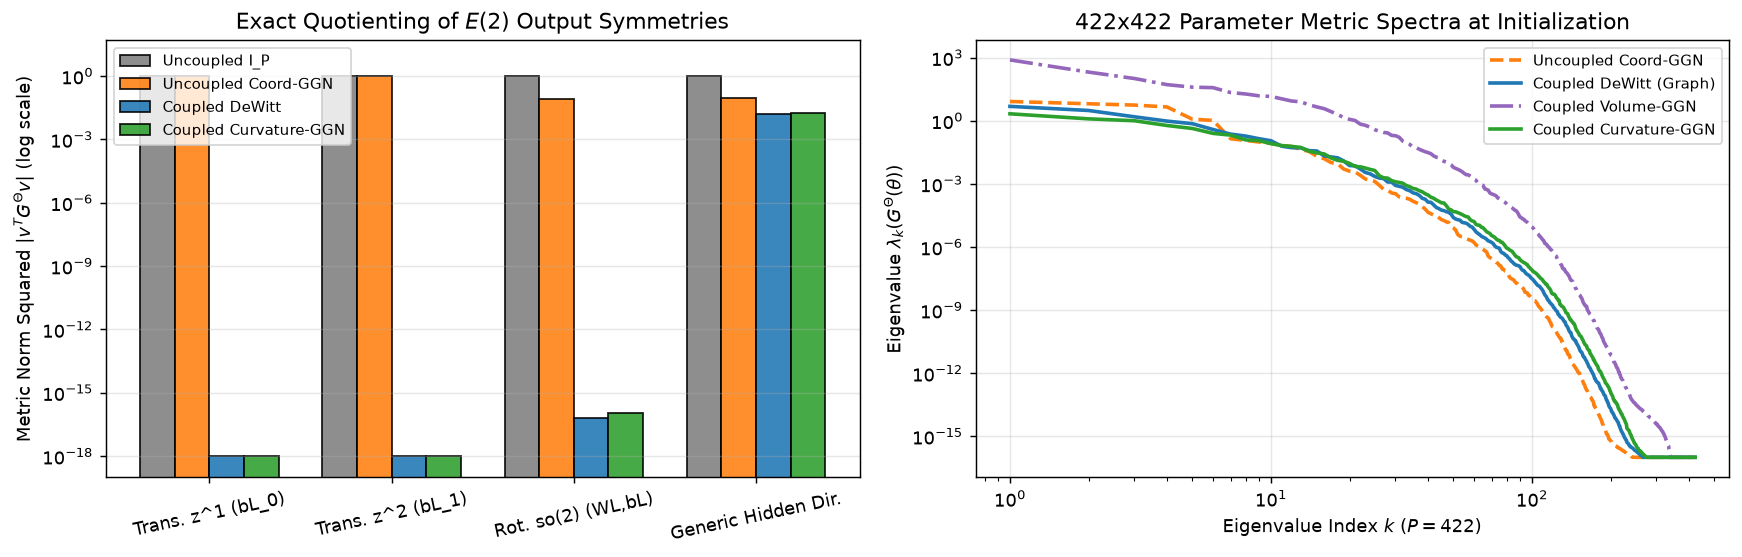

In [2]:
probe_model = MoonsMLP(
    layer_dims=LAYER_DIMS,
    activation=HIDDEN_ACTIVATION,
    output_activation=OUTPUT_ACTIVATION,
    seed=7,
)
L = probe_model.num_layers
last_idx = L - 1
d_out = probe_model.layer_dims[-1]
P_total = sum(p.numel() for p in probe_model.parameters())
params_probe = {k: v.detach() for k, v in probe_model.named_parameters()}

# 1. Verify Gauss-equation curvature equivalence to float64 machine precision
ref_geom = compute_layer_geometry(probe_model, X_train[:64], layer_idx=L, metric_mode="graph", params=params_probe)
g_fast, K_fast = compute_fast_graph_geometry(probe_model, X_train[:64], params=params_probe)
print(f"Gauss Equation Consistency | max |g_fast - g_ref| = {(g_fast - ref_geom['g']).abs().max().item():.2e}")
print(f"Gauss Equation Consistency | max |K_fast - K_ref| = {(K_fast - ref_geom['K']).abs().max().item():.2e}\n")

# 2. Construct unit parameter vectors for output symmetry generators + a generic hidden direction
def build_unit_param_direction(overrides: dict, seed_random: int | None = None) -> torch.Tensor:
    if seed_random is not None:
        gen = torch.Generator().manual_seed(seed_random)
        raw = torch.randn(P_total, generator=gen, dtype=torch.float64)
        return raw / raw.norm()
    chunks = []
    for k, p in params_probe.items():
        if k in overrides:
            chunks.append(overrides[k].reshape(-1))
        else:
            chunks.append(torch.zeros_like(p).reshape(-1))
    vec = torch.cat(chunks)
    return vec / vec.norm()

b_e1 = torch.zeros(d_out, dtype=torch.float64)
b_e1[0] = 1.0
b_e2 = torch.zeros(d_out, dtype=torch.float64)
b_e2[min(1, d_out - 1)] = 1.0
omega = torch.zeros((d_out, d_out), dtype=torch.float64)
if d_out >= 2:
    omega[0, 1] = -1.0
    omega[1, 0] = 1.0

directions = [
    ("Trans. z^1 (bL_0)", build_unit_param_direction({f"layers.{last_idx}.bias": b_e1})),
    ("Trans. z^2 (bL_1)", build_unit_param_direction({f"layers.{last_idx}.bias": b_e2})),
    ("Rot. so(2) (WL,bL)", build_unit_param_direction({
        f"layers.{last_idx}.weight": omega @ params_probe[f"layers.{last_idx}.weight"],
        f"layers.{last_idx}.bias": omega @ params_probe[f"layers.{last_idx}.bias"],
    })),
    ("Generic Hidden Dir.", build_unit_param_direction({}, seed_random=123)),
]

G_eucl = torch.eye(P_total, dtype=torch.float64)
G_coord_0 = compute_uncoupled_coord_metric(probe_model, X_train, damping=0.0)
G_dewitt_0 = compute_coupled_dewitt_metric(probe_model, X_train, metric_mode="graph", damping=0.0)
G_coup_vol_0 = compute_coupled_geometric_metric(probe_model, X_train, y_train, task="volume", margin=0.60, damping=0.0, n_classes=N_CLASSES)
G_coup_curv_0 = compute_coupled_geometric_metric(probe_model, X_train, y_train, task="curvature", margin=0.40, damping=0.0, n_classes=N_CLASSES)

metric_mats = [
    ("Uncoupled I_P", G_eucl, "#7f7f7f"),
    ("Uncoupled Coord-GGN", G_coord_0, "#ff7f0e"),
    ("Coupled DeWitt", G_dewitt_0, "#1f77b4"),
    ("Coupled Curvature-GGN", G_coup_curv_0, "#2ca02c"),
]

print(f"{'Parameter Direction':<22} | {'Uncoupled I_P':>14} | {'Uncoupled Coord':>15} | {'Coupled DeWitt':>15} | {'Coupled Curv-GGN':>16}")
print("-" * 94)
quad_table = {m_name: [] for m_name, _, _ in metric_mats}
for d_name, v in directions:
    vals = []
    for m_name, G_mat, _ in metric_mats:
        q = abs(float(v @ (G_mat @ v)))
        quad_table[m_name].append(max(q, 1e-18))
        vals.append(q)
    print(f"{d_name:<22} | {vals[0]:14.3e} | {vals[1]:15.3e} | {vals[2]:15.3e} | {vals[3]:16.3e}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

x_pos = np.arange(len(directions))
bar_w = 0.19
for idx, (m_name, _, col) in enumerate(metric_mats):
    axes[0].bar(x_pos + (idx - 1.5) * bar_w, quad_table[m_name], width=bar_w, color=col, edgecolor="k", alpha=0.88, label=m_name)
axes[0].set_yscale("log")
axes[0].set_ylim(1e-19, 5e1)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels([d[0] for d in directions], rotation=12)
axes[0].set_ylabel(r"Metric Norm Squared $|v^T G^\Theta v|$ (log scale)")
axes[0].set_title(r"Exact Quotienting of $E(2)$ Output Symmetries")
axes[0].legend(fontsize=8.5, loc="upper left")
axes[0].grid(axis="y", alpha=0.3)

spec_items = [
    ("Uncoupled Coord-GGN", G_coord_0, "#ff7f0e", "--"),
    ("Coupled DeWitt (Graph)", G_dewitt_0, "#1f77b4", "-"),
    ("Coupled Volume-GGN", G_coup_vol_0, "#9467bd", "-."),
    ("Coupled Curvature-GGN", G_coup_curv_0, "#2ca02c", "-"),
]
for label, G_m, col, ls in spec_items:
    ev = torch.linalg.eigvalsh(G_m).flip(0).clamp(min=1e-16).numpy()
    axes[1].plot(range(1, len(ev) + 1), ev, lw=2.0, color=col, ls=ls, label=label)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel(f"Eigenvalue Index $k$ ($P = {P_total}$)")
axes[1].set_ylabel(r"Eigenvalue $\lambda_k(G^\Theta(\theta))$")
axes[1].set_title(f"{P_total}x{P_total} Parameter Metric Spectra at Initialization")
axes[1].legend(fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Coupled vs. Uncoupled Optimization Across All Three Purely Geometric Losses

We now train identical configured MLPs (`seed = 7`) for **45 optimization steps** across all three purely geometric classification paradigms, comparing **Uncoupled Euclidean GD**, **Uncoupled Adam**, **Uncoupled Coord-NGD** ($G^{\Theta,\text{coord}}$), and **Coupled Geom-NGD** ($G^{\Theta,\text{coupled}}$).

Geometric Task | Optimizer             | Step 10 Acc | Step 25 Acc | Final Loss | Final Test Acc | bL Gauge Drift
----------------------------------------------------------------------------------------------------------------
volume        | Uncoupled GD (I_P)    |      86.67% |      94.17% |     0.1008 |         97.50% |      0.000e+00
volume        | Uncoupled Adam        |      89.17% |      95.00% |     0.0697 |         99.17% |      0.000e+00
volume        | Uncoupled Coord-NGD   |      94.17% |      90.83% |     0.1535 |         94.17% |      4.645e-01
volume        | Coupled Geom-NGD      |      60.83% |      95.83% |     0.0784 |         95.00% |      0.000e+00
----------------------------------------------------------------------------------------------------------------
anisotropy    | Uncoupled GD (I_P)    |      54.17% |      52.50% |     0.4477 |         56.67% |      0.000e+00
anisotropy    | Uncoupled Adam        |      60.83% |      84.17% |     0.1223 |         99.17%

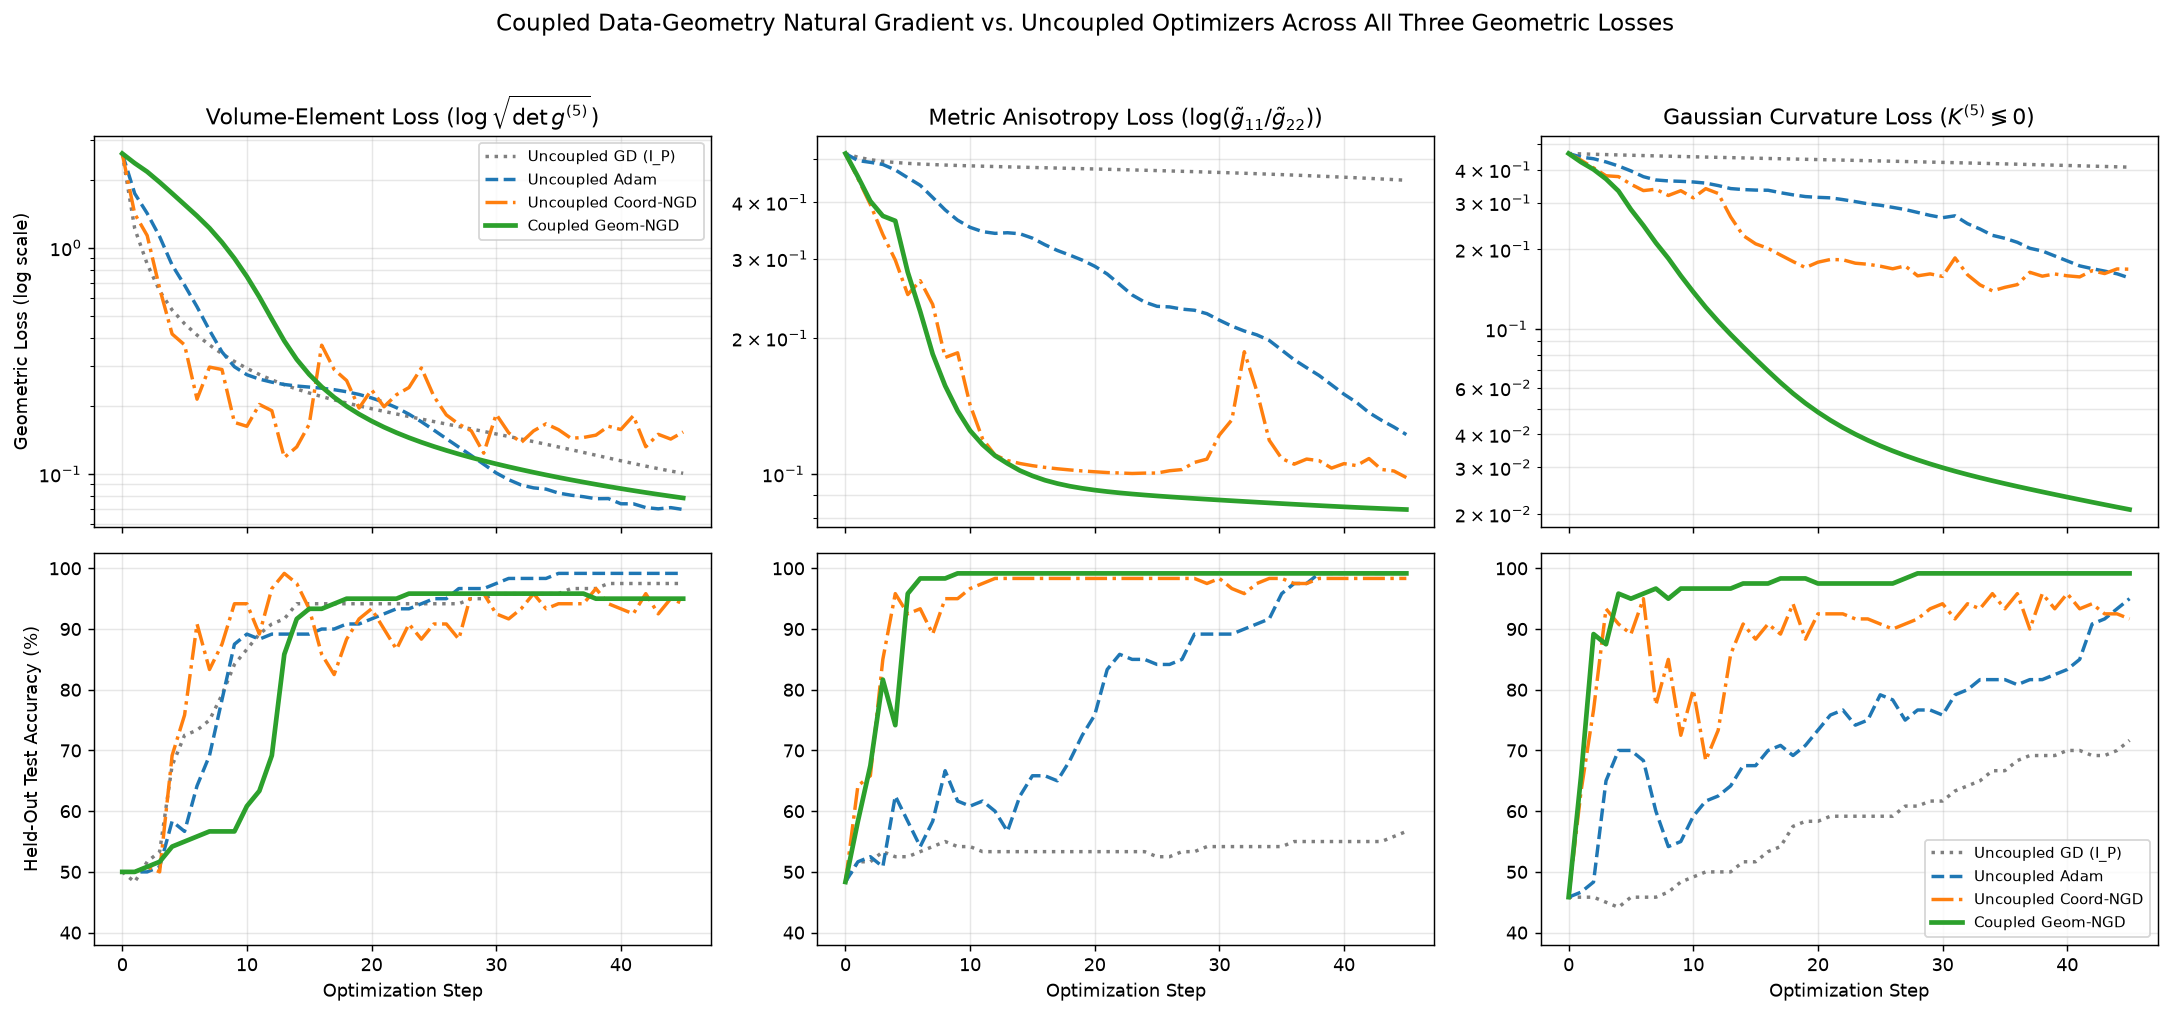

In [3]:
TASK_CONFIGS = {
    "volume": {
        "title": rf"Volume-Element Loss ($\log\sqrt{{\det g^{{({L})}}}}$)",
        "margin": 0.60,
        "gd_lr": 0.08,
        "adam_lr": 0.02,
        "coord_lr": 0.22,
        "coupled_lr": 0.32,
        "dewitt_weight": 0.30,
        "damping": 0.025,
    },
    "anisotropy": {
        "title": r"Metric Anisotropy Loss ($\log(\tilde{g}_{11}/\tilde{g}_{22})$)",
        "margin": 0.45,
        "gd_lr": 0.08,
        "adam_lr": 0.02,
        "coord_lr": 0.22,
        "coupled_lr": 0.32,
        "dewitt_weight": 0.25,
        "damping": 0.020,
    },
    "curvature": {
        "title": rf"Gaussian Curvature Loss ($K^{{({L})}} \lessgtr 0$)",
        "margin": 0.40,
        "gd_lr": 0.04,
        "adam_lr": 0.02,
        "coord_lr": 0.12,
        "coupled_lr": 0.28,
        "dewitt_weight": 0.20,
        "damping": 0.025,
    },
}


def evaluate_geometric_task(model: MoonsMLP, X_tr: torch.Tensor, y_tr: torch.Tensor, X_te: torch.Tensor, y_te: torch.Tensor, task: str, margin: float):
    params = dict(model.named_parameters())
    l_out = model.num_layers
    if task == "volume":
        g_tr = compute_layer_pullback_metric(model, X_tr, layer_idx=l_out, metric_mode="euclidean", eps=1e-6, params=params)
        loss, metrics = volume_contrastive_loss(g_tr, y_tr, margin=margin, n_classes=N_CLASSES)
        with torch.no_grad():
            g_te = compute_layer_pullback_metric(model, X_te, layer_idx=l_out, metric_mode="euclidean", eps=1e-6)
            psi_te = 0.5 * torch.log(torch.clamp(torch.linalg.det(g_te), min=1e-8))
            te_acc = (scalar_geometric_predict(psi_te, n_classes=N_CLASSES, margin=margin) == y_te).float().mean().item()
        return loss, metrics["geom_acc"], te_acc

    if task == "anisotropy":
        g_tr = compute_layer_pullback_metric(model, X_tr, layer_idx=l_out, metric_mode="graph", params=params)
        loss, metrics = anisotropy_margin_loss(g_tr, y_tr, margin=margin, n_classes=N_CLASSES)
        with torch.no_grad():
            g_te = compute_layer_pullback_metric(model, X_te, layer_idx=l_out, metric_mode="graph")
            psi_te = torch.log(torch.clamp(g_te[:, 0, 0], min=1e-8) / torch.clamp(g_te[:, 1, 1], min=1e-8))
            te_acc = (scalar_geometric_predict(psi_te, n_classes=N_CLASSES, margin=margin) == y_te).float().mean().item()
        return loss, metrics["geom_acc"], te_acc

    if task == "curvature":
        g_tr, K_tr = compute_fast_graph_geometry(model, X_tr, params=params)
        loss, metrics = curvature_margin_loss(K_tr, y_tr, g_tr, margin=margin, lambda_vol=0.02, lambda_iso=0.005, k_clip=10.0, n_classes=N_CLASSES)
        with torch.no_grad():
            _, K_te = compute_fast_graph_geometry(model, X_te)
            te_acc = (scalar_geometric_predict(K_te, n_classes=N_CLASSES, margin=margin) == y_te).float().mean().item()
        return loss, metrics["geom_acc"], te_acc

    raise ValueError(task)


def train_geometric_optimizer(task: str, opt_kind: str, n_steps: int = 45, seed: int = 7):
    cfg = TASK_CONFIGS[task]
    margin = cfg["margin"]
    mdl = MoonsMLP(
        layer_dims=LAYER_DIMS,
        activation=HIDDEN_ACTIVATION,
        output_activation=OUTPUT_ACTIVATION,
        seed=seed,
    )
    bL_init = mdl.layers[-1].bias.detach().clone()

    adam_opt = torch.optim.Adam(mdl.parameters(), lr=cfg["adam_lr"]) if opt_kind == "adam" else None
    hist = {"loss": [], "train_acc": [], "test_acc": [], "b5_drift": [], "time_s": []}
    t_start = time.perf_counter()

    for step in range(n_steps):
        mdl.zero_grad()
        loss, tr_acc, te_acc = evaluate_geometric_task(mdl, X_train, y_train, X_test, y_test, task, margin)
        b_drift = (mdl.layers[-1].bias.detach() - bL_init).norm().item()

        hist["loss"].append(loss.item())
        hist["train_acc"].append(tr_acc * 100.0)
        hist["test_acc"].append(te_acc * 100.0)
        hist["b5_drift"].append(b_drift)
        hist["time_s"].append(time.perf_counter() - t_start)

        loss.backward()

        if opt_kind == "gd":
            if task == "curvature":
                torch.nn.utils.clip_grad_norm_(mdl.parameters(), max_norm=5.0)
            with torch.no_grad():
                for p in mdl.parameters():
                    if p.grad is not None:
                        p -= cfg["gd_lr"] * p.grad
        elif opt_kind == "adam":
            if task == "curvature":
                torch.nn.utils.clip_grad_norm_(mdl.parameters(), max_norm=5.0)
            adam_opt.step()
        elif opt_kind in ("coord_ngd", "coupled_ngd"):
            grad_flat = torch.cat([
                p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_train.dtype, device=X_train.device)
                for p in mdl.parameters()
            ])
            if opt_kind == "coord_ngd":
                G_mat = compute_uncoupled_coord_metric(mdl, X_train, damping=cfg["damping"])
                lr = cfg["coord_lr"]
            else:
                G_mat = compute_coupled_geometric_metric(
                    mdl,
                    X_train,
                    y_train,
                    task=task,
                    margin=margin,
                    dewitt_weight=cfg["dewitt_weight"],
                    damping=cfg["damping"],
                    n_classes=N_CLASSES,
                )
                lr = cfg["coupled_lr"]

            nat_dir = torch.linalg.solve(G_mat, grad_flat)
            riem_norm = torch.sqrt(torch.clamp(nat_dir @ (G_mat @ nat_dir), min=1e-12)).item()
            trust_scale = min(1.0, 0.85 / riem_norm)
            with torch.no_grad():
                offset = 0
                for p in mdl.parameters():
                    n = p.numel()
                    p -= (lr * trust_scale) * nat_dir[offset : offset + n].reshape(p.shape)
                    offset += n
        else:
            raise ValueError(opt_kind)

    loss_f, tr_f, te_f = evaluate_geometric_task(mdl, X_train, y_train, X_test, y_test, task, margin)
    hist["loss"].append(loss_f.item())
    hist["train_acc"].append(tr_f * 100.0)
    hist["test_acc"].append(te_f * 100.0)
    hist["b5_drift"].append((mdl.layers[-1].bias.detach() - bL_init).norm().item())
    hist["time_s"].append(time.perf_counter() - t_start)

    return mdl, hist


OPTIMIZER_SPECS = [
    ("gd", "Uncoupled GD (I_P)", "#7f7f7f", ":"),
    ("adam", "Uncoupled Adam", "#1f77b4", "--"),
    ("coord_ngd", "Uncoupled Coord-NGD", "#ff7f0e", "-."),
    ("coupled_ngd", "Coupled Geom-NGD", "#2ca02c", "-"),
]

N_STEPS = 45
all_runs = {t: {} for t in ["volume", "anisotropy", "curvature"]}

print(f"{'Geometric Task':<13} | {'Optimizer':<21} | {'Step 10 Acc':>11} | {'Step 25 Acc':>11} | {'Final Loss':>10} | {'Final Test Acc':>14} | {'bL Gauge Drift':>14}")
print("-" * 112)

for task_name in ["volume", "anisotropy", "curvature"]:
    for opt_key, opt_label, _, _ in OPTIMIZER_SPECS:
        mdl_trained, h = train_geometric_optimizer(task_name, opt_key, n_steps=N_STEPS, seed=7)
        all_runs[task_name][opt_key] = (mdl_trained, h)
        print(
            f"{task_name:<13} | {opt_label:<21} | {h['test_acc'][10]:10.2f}% | {h['test_acc'][25]:10.2f}% | "
            f"{h['loss'][-1]:10.4f} | {h['test_acc'][-1]:13.2f}% | {h['b5_drift'][-1]:14.3e}"
        )
    print("-" * 112)

fig, axes = plt.subplots(2, 3, figsize=(16.8, 7.6), sharex=True)
steps_axis = np.arange(N_STEPS + 1)

for col_idx, task_name in enumerate(["volume", "anisotropy", "curvature"]):
    for opt_key, opt_label, col, ls in OPTIMIZER_SPECS:
        _, h = all_runs[task_name][opt_key]
        lw = 2.6 if opt_key == "coupled_ngd" else 1.9
        axes[0, col_idx].plot(steps_axis, h["loss"], color=col, ls=ls, lw=lw, label=opt_label)
        axes[1, col_idx].plot(steps_axis, h["test_acc"], color=col, ls=ls, lw=lw, label=opt_label)

    axes[0, col_idx].set_yscale("log")
    axes[0, col_idx].set_title(TASK_CONFIGS[task_name]["title"])
    axes[0, col_idx].grid(alpha=0.3, which="both")

    axes[1, col_idx].set_ylim(min(38.0, 100.0 / N_CLASSES - 10.0), 102.5)
    axes[1, col_idx].set_xlabel("Optimization Step")
    axes[1, col_idx].grid(alpha=0.3)

axes[0, 0].set_ylabel("Geometric Loss (log scale)")
axes[1, 0].set_ylabel("Held-Out Test Accuracy (%)")
axes[0, 0].legend(fontsize=8.5, loc="upper right")
axes[1, 2].legend(fontsize=8.5, loc="lower right")

plt.suptitle("Coupled Data-Geometry Natural Gradient vs. Uncoupled Optimizers Across All Three Geometric Losses", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

## 3. $3 \times 4$ Spatial Decision Landscapes: Coupled vs. Uncoupled Learned Manifolds

To inspect how parameter-data metric coupling shapes the learned representation manifold in ambient input space $(x^1, x^2)$, we plot the learned target geometric field $\psi(x^1, x^2)$ after 45 steps across all **3 geometric objectives (rows)** and **4 optimizers (columns)**.

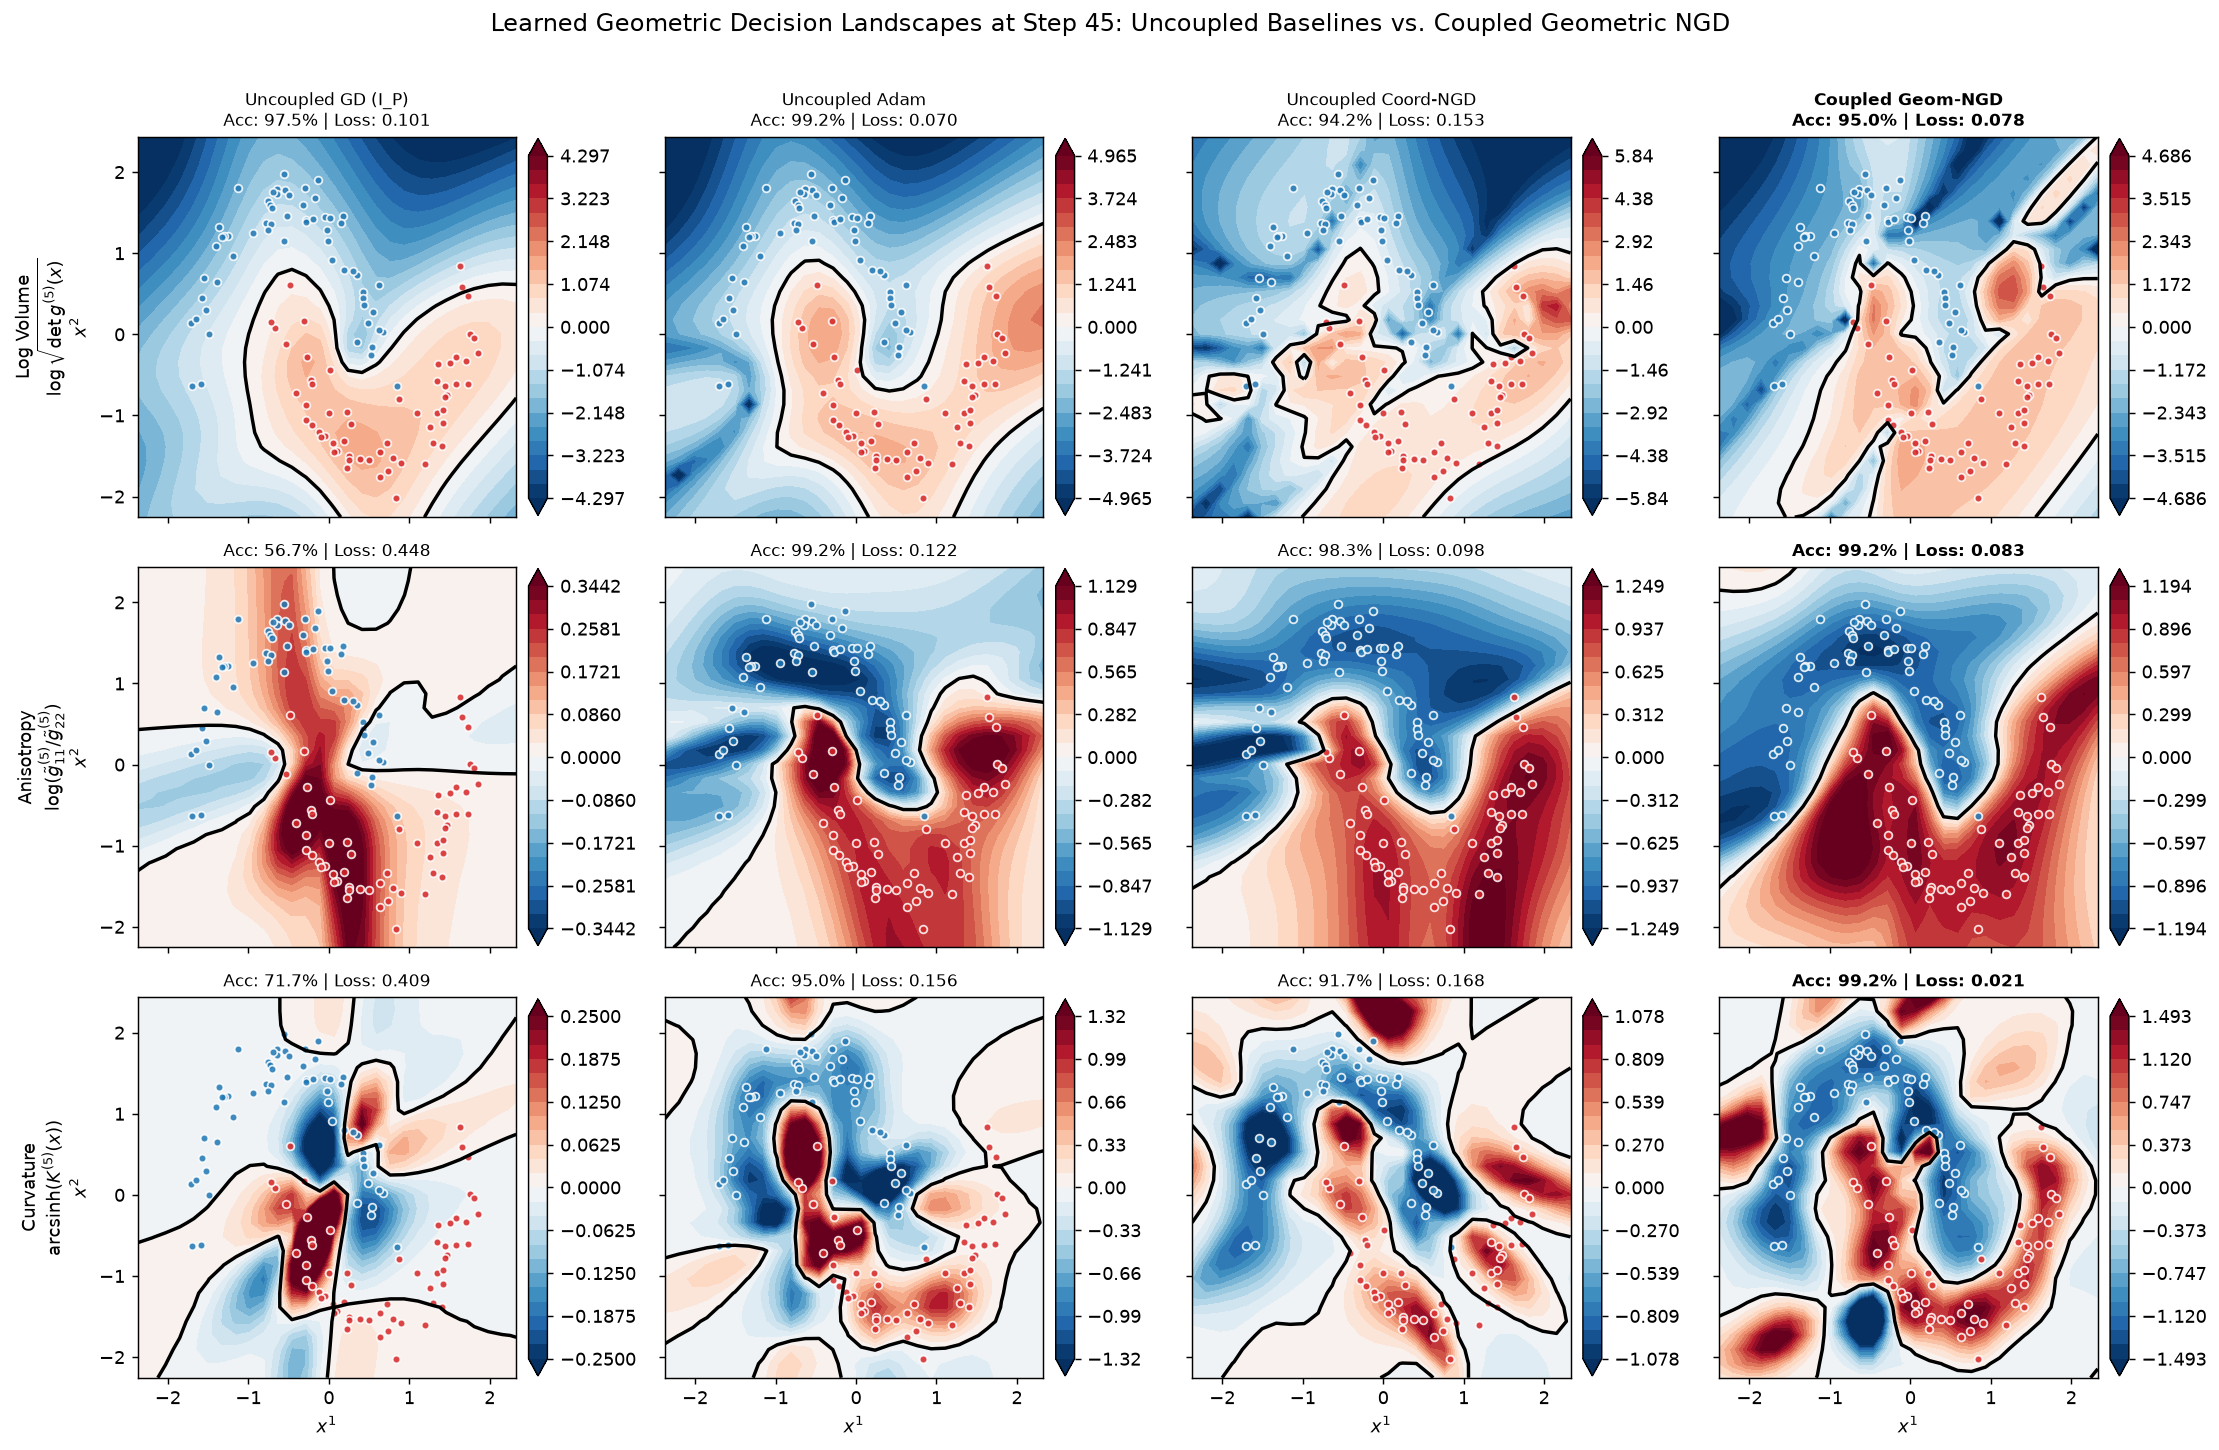

In [4]:
def eval_target_field_on_points(mdl: MoonsMLP, pts: torch.Tensor, task: str) -> np.ndarray:
    l_out = mdl.num_layers
    if task == "volume":
        g = compute_layer_pullback_metric(mdl, pts, layer_idx=l_out, metric_mode="euclidean", eps=1e-6)
        return (0.5 * torch.log(torch.clamp(torch.linalg.det(g), min=1e-8))).detach().numpy()
    if task == "anisotropy":
        g = compute_layer_pullback_metric(mdl, pts, layer_idx=l_out, metric_mode="graph")
        return torch.log(torch.clamp(g[:, 0, 0], min=1e-8) / torch.clamp(g[:, 1, 1], min=1e-8)).detach().numpy()
    if task == "curvature":
        _, K = compute_fast_graph_geometry(mdl, pts)
        return np.arcsinh(K.detach().numpy())
    raise ValueError(task)

row_specs = [
    ("volume", "Log Volume\n" + rf"$\log\sqrt{{\det g^{{({L})}}(x)}}$"),
    ("anisotropy", "Anisotropy\n" + rf"$\log(\tilde{{g}}^{{({L})}}_{{11}}/\tilde{{g}}^{{({L})}}_{{22}})$"),
    ("curvature", "Curvature\n" + rf"$\mathrm{{arcsinh}}(K^{{({L})}}(x))$"),
]

fig, axes = plt.subplots(3, 4, figsize=(17.2, 11.0), sharex=True, sharey=True)

for r_idx, (task_name, row_lbl) in enumerate(row_specs):
    for c_idx, (opt_key, opt_label, _, _) in enumerate(OPTIMIZER_SPECS):
        ax = axes[r_idx, c_idx]
        mdl, h = all_runs[task_name][opt_key]
        fld = eval_target_field_on_points(mdl, grid_pts, task_name).reshape(xx.shape)
        vm = float(max(np.percentile(np.abs(fld), 96), 0.25))
        norm = TwoSlopeNorm(vmin=-vm, vcenter=0.0, vmax=vm)

        im = ax.contourf(xx, yy, fld, levels=np.linspace(-vm, vm, 25), cmap="RdBu_r", norm=norm, extend="both")
        if fld.min() < 0.0 < fld.max():
            ax.contour(xx, yy, fld, levels=[0.0], colors="k", linewidths=1.9)

        for c in range(N_CLASSES):
            mc = y_test == c
            ax.scatter(X_test[mc, 0], X_test[mc, 1], c=CLASS_COLORS[c % len(CLASS_COLORS)], edgecolors="w", s=18, alpha=0.85)

        acc_final = h["test_acc"][-1]
        loss_final = h["loss"][-1]
        is_coupled = opt_key == "coupled_ngd"
        header = f"{opt_label}\n" if r_idx == 0 else ""
        ax.set_title(
            f"{header}Acc: {acc_final:.1f}% | Loss: {loss_final:.3f}",
            fontsize=9.5,
            fontweight="bold" if is_coupled else "normal",
        )
        if c_idx == 0:
            ax.set_ylabel(f"{row_lbl}\n$x^2$", fontsize=10)
        if r_idx == 2:
            ax.set_xlabel("$x^1$", fontsize=10)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

plt.suptitle("Learned Geometric Decision Landscapes at Step 45: Uncoupled Baselines vs. Coupled Geometric NGD", y=1.01, fontsize=13.5)
plt.tight_layout()
plt.show()

## 4. Mechanistic Diagnostics: Spurious Gauge Drift & Unclipped Curvature Stiffness

Comparing the optimization trajectories exposes **two fundamental geometric mechanisms** distinguishing coupled from uncoupled parameter metrics:
1. **Elimination of Cross-Covariance Gauge Drift (`Uncoupled Coord-NGD` vs. `Coupled Geom-NGD`)**.
2. **Intrinsic Stiffness Preconditioning Without Gradient Clipping**.

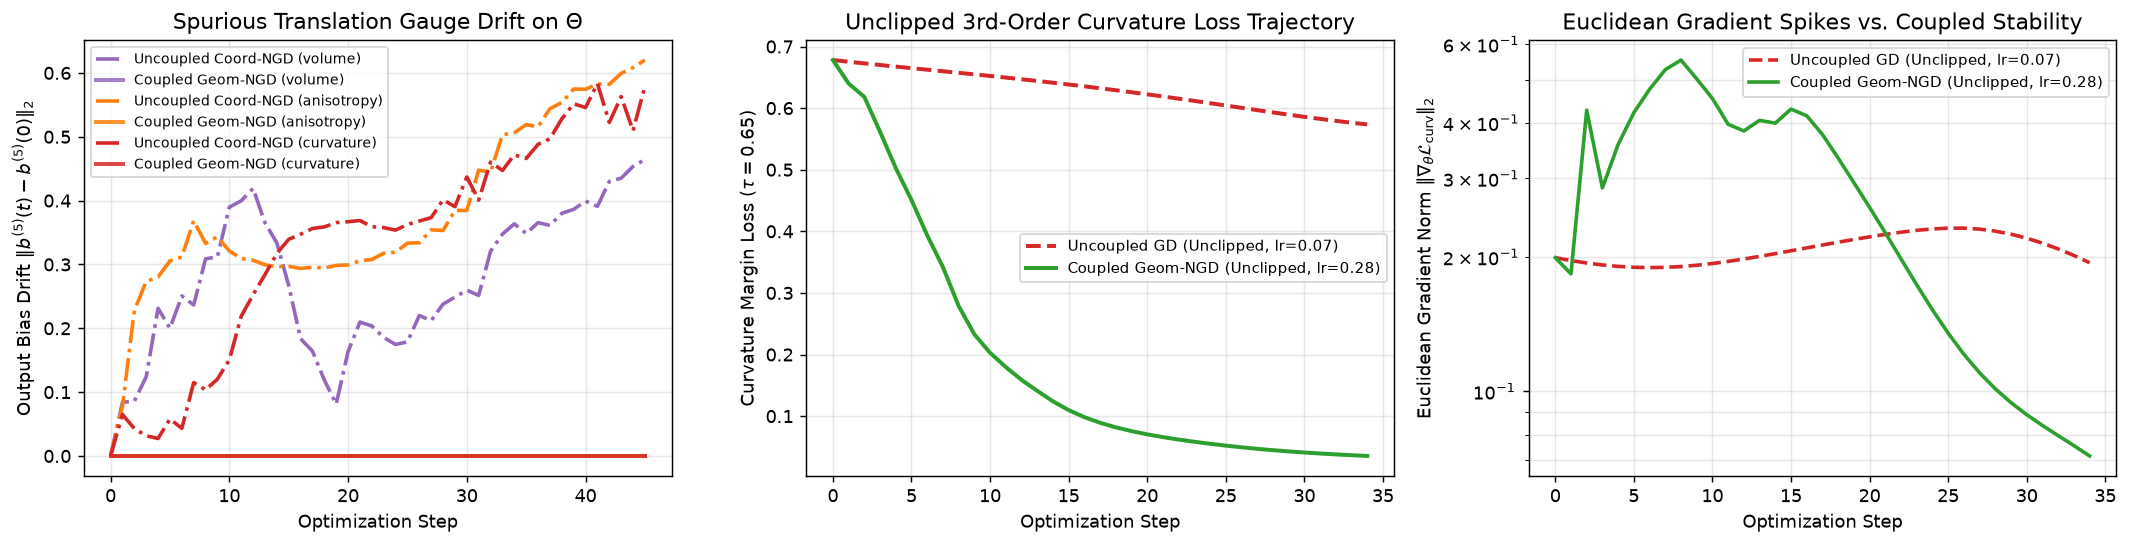

In [5]:
def run_unclipped_curvature_stiffness_test(steps: int = 35):
    results_stiff = {}
    for mode_name, lr in [("Uncoupled GD (Unclipped, lr=0.07)", 0.07), ("Coupled Geom-NGD (Unclipped, lr=0.28)", 0.28)]:
        mdl = MoonsMLP(
            layer_dims=LAYER_DIMS,
            activation=HIDDEN_ACTIVATION,
            output_activation=OUTPUT_ACTIVATION,
            seed=7,
        )
        losses, grad_norms, test_accs = [], [], []

        for _ in range(steps):
            mdl.zero_grad()
            params = dict(mdl.named_parameters())
            g_tr, K_tr = compute_fast_graph_geometry(mdl, X_train, params=params)
            loss, _ = curvature_margin_loss(K_tr, y_train, g_tr, margin=0.65, lambda_vol=0.02, lambda_iso=0.005, k_clip=25.0, n_classes=N_CLASSES)
            loss.backward()

            g_flat = torch.cat([
                p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_train.dtype)
                for p in mdl.parameters()
            ])
            grad_norms.append(g_flat.norm().item())
            losses.append(loss.item())

            with torch.no_grad():
                _, K_te = compute_fast_graph_geometry(mdl, X_test)
                preds_k = scalar_geometric_predict(K_te, n_classes=N_CLASSES, margin=0.65)
                test_accs.append((preds_k == y_test).float().mean().item() * 100.0)

            if "Uncoupled" in mode_name:
                with torch.no_grad():
                    for p in mdl.parameters():
                        if p.grad is not None:
                            p -= lr * p.grad
            else:
                G_c = compute_coupled_geometric_metric(
                    mdl, X_train, y_train, task="curvature", margin=0.65, k_clip=25.0, dewitt_weight=0.20, damping=0.025, n_classes=N_CLASSES
                )
                nat_step = torch.linalg.solve(G_c, g_flat)
                r_norm = torch.sqrt(torch.clamp(nat_step @ (G_c @ nat_step), min=1e-12)).item()
                scale = min(1.0, 0.85 / r_norm)
                with torch.no_grad():
                    offset = 0
                    for p in mdl.parameters():
                        n = p.numel()
                        p -= (lr * scale) * nat_step[offset : offset + n].reshape(p.shape)
                        offset += n

        results_stiff[mode_name] = {"loss": losses, "grad_norm": grad_norms, "test_acc": test_accs}
    return results_stiff

stiff_res = run_unclipped_curvature_stiffness_test(steps=35)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.3))

task_colors = {"volume": "#9467bd", "anisotropy": "#ff7f0e", "curvature": "#d62728"}
for t_name, t_col in task_colors.items():
    axes[0].plot(all_runs[t_name]["coord_ngd"][1]["b5_drift"], ls="-.", lw=2.0, color=t_col, label=f"Uncoupled Coord-NGD ({t_name})")
    axes[0].plot(all_runs[t_name]["coupled_ngd"][1]["b5_drift"], ls="-", lw=2.2, color=t_col, alpha=0.85, label=f"Coupled Geom-NGD ({t_name})")

axes[0].set_xlabel("Optimization Step")
axes[0].set_ylabel(rf"Output Bias Drift $\|b^{{({L})}}(t) - b^{{({L})}}(0)\|_2$")
axes[0].set_title(r"Spurious Translation Gauge Drift on $\Theta$")
axes[0].legend(fontsize=7.5, ncol=1, loc="upper left")
axes[0].grid(alpha=0.3)

for label, col, ls in [
    ("Uncoupled GD (Unclipped, lr=0.07)", "#d62728", "--"),
    ("Coupled Geom-NGD (Unclipped, lr=0.28)", "#2ca02c", "-"),
]:
    axes[1].plot(stiff_res[label]["loss"], color=col, ls=ls, lw=2.2, label=label)
    axes[2].plot(stiff_res[label]["grad_norm"], color=col, ls=ls, lw=2.0, label=label)

axes[1].set_xlabel("Optimization Step")
axes[1].set_ylabel(r"Curvature Margin Loss ($\tau = 0.65$)")
axes[1].set_title("Unclipped 3rd-Order Curvature Loss Trajectory")
axes[1].legend(fontsize=8.2)
axes[1].grid(alpha=0.3)

axes[2].set_yscale("log")
axes[2].set_xlabel("Optimization Step")
axes[2].set_ylabel(r"Euclidean Gradient Norm $\|\nabla_\theta \mathcal{L}_{\mathrm{curv}}\|_2$")
axes[2].set_title("Euclidean Gradient Spikes vs. Coupled Stability")
axes[2].legend(fontsize=8.2)
axes[2].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

## 5. Ablation: Universal Unsupervised DeWitt Metric ($G^{\Theta,\text{DeWitt}}$) vs. Task-Coupled Metric ($G^{\Theta,\text{coupled}}$)

Task         | Uncoupled GD Final Loss (Acc)    | Pure DeWitt-NGD Final Loss (Acc)   | Task-Coupled NGD Final Loss (Acc) 
------------------------------------------------------------------------------------------------------------------------
volume       |   0.1008 ( 97.50%)               |   0.1203 ( 97.50%)                 |   0.0784 ( 95.00%)
anisotropy   |   0.4477 ( 56.67%)               |   0.0824 ( 99.17%)                 |   0.0834 ( 99.17%)
curvature    |   0.4089 ( 71.67%)               |   0.0218 ( 97.50%)                 |   0.0208 ( 99.17%)


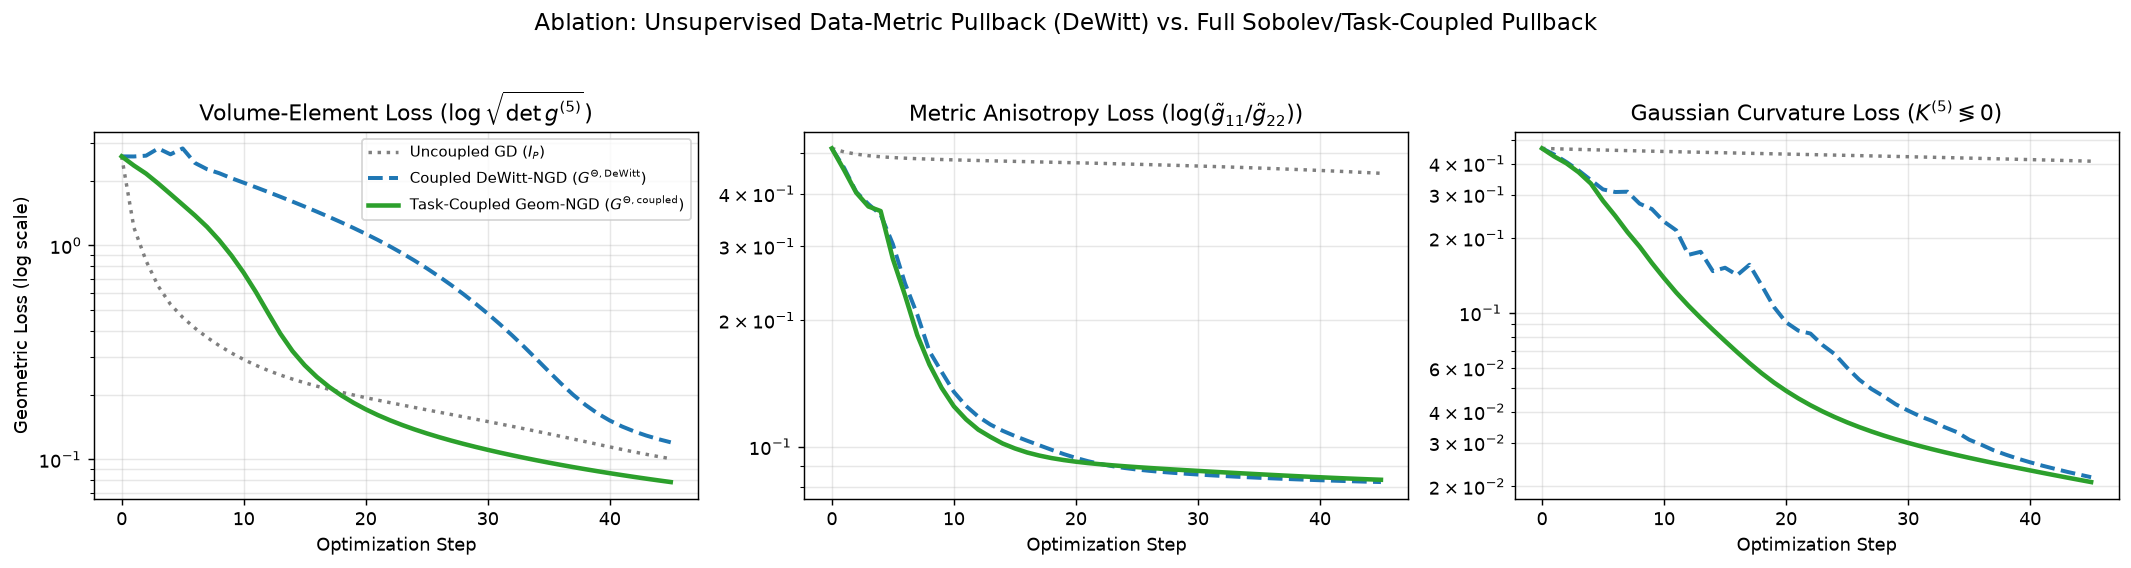

In [6]:
def train_pure_dewitt_ngd(task: str, n_steps: int = 45, seed: int = 7):
    cfg = TASK_CONFIGS[task]
    margin = cfg["margin"]
    m_mode = "euclidean" if task == "volume" else "graph"
    mdl = MoonsMLP(
        layer_dims=LAYER_DIMS,
        activation=HIDDEN_ACTIVATION,
        output_activation=OUTPUT_ACTIVATION,
        seed=seed,
    )
    hist = {"loss": [], "test_acc": []}

    for _ in range(n_steps):
        mdl.zero_grad()
        loss, _, te_acc = evaluate_geometric_task(mdl, X_train, y_train, X_test, y_test, task, margin)
        hist["loss"].append(loss.item())
        hist["test_acc"].append(te_acc * 100.0)
        loss.backward()

        g_flat = torch.cat([
            p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_train.dtype)
            for p in mdl.parameters()
        ])
        G_dw = compute_coupled_dewitt_metric(mdl, X_train, metric_mode=m_mode, eps=1e-6, inv_eps=1e-3, damping=cfg["damping"])
        nat_dir = torch.linalg.solve(G_dw, g_flat)
        r_norm = torch.sqrt(torch.clamp(nat_dir @ (G_dw @ nat_dir), min=1e-12)).item()
        scale = min(1.0, 0.85 / r_norm)
        lr_dw = 0.35 if task != "curvature" else 0.20
        with torch.no_grad():
            offset = 0
            for p in mdl.parameters():
                n = p.numel()
                p -= (lr_dw * scale) * nat_dir[offset : offset + n].reshape(p.shape)
                offset += n

    loss_f, _, te_f = evaluate_geometric_task(mdl, X_train, y_train, X_test, y_test, task, margin)
    hist["loss"].append(loss_f.item())
    hist["test_acc"].append(te_f * 100.0)
    return hist

dewitt_runs = {t: train_pure_dewitt_ngd(t, n_steps=N_STEPS, seed=7) for t in ["volume", "anisotropy", "curvature"]}

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2), sharey=False)
for idx, task_name in enumerate(["volume", "anisotropy", "curvature"]):
    axes[idx].plot(all_runs[task_name]["gd"][1]["loss"], ":", lw=1.9, color="#7f7f7f", label=r"Uncoupled GD ($I_P$)")
    axes[idx].plot(dewitt_runs[task_name]["loss"], "--", lw=2.2, color="#1f77b4", label=r"Coupled DeWitt-NGD ($G^{\Theta,\mathrm{DeWitt}}$)")
    axes[idx].plot(all_runs[task_name]["coupled_ngd"][1]["loss"], "-", lw=2.5, color="#2ca02c", label=r"Task-Coupled Geom-NGD ($G^{\Theta,\mathrm{coupled}}$)")
    axes[idx].set_yscale("log")
    axes[idx].set_xlabel("Optimization Step")
    axes[idx].set_title(TASK_CONFIGS[task_name]["title"])
    axes[idx].grid(alpha=0.3, which="both")

axes[0].set_ylabel("Geometric Loss (log scale)")
axes[0].legend(fontsize=8.3)
plt.suptitle("Ablation: Unsupervised Data-Metric Pullback (DeWitt) vs. Full Sobolev/Task-Coupled Pullback", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

print(f"{'Task':<12} | {'Uncoupled GD Final Loss (Acc)':<32} | {'Pure DeWitt-NGD Final Loss (Acc)':<34} | {'Task-Coupled NGD Final Loss (Acc)':<34}")
print("-" * 120)
for t in ["volume", "anisotropy", "curvature"]:
    h_gd = all_runs[t]["gd"][1]
    h_dw = dewitt_runs[t]
    h_cp = all_runs[t]["coupled_ngd"][1]
    print(
        f"{t:<12} | {h_gd['loss'][-1]:8.4f} ({h_gd['test_acc'][-1]:6.2f}%)               | "
        f"{h_dw['loss'][-1]:8.4f} ({h_dw['test_acc'][-1]:6.2f}%)                 | "
        f"{h_cp['loss'][-1]:8.4f} ({h_cp['test_acc'][-1]:6.2f}%)"
    )